# 19. Klasifikasi Audio Berisik vs Non-Berisik (Model 4.0 - Pure SVM Teroptimasi)

**Tujuan:** Mengoptimalkan model tunggal **Support Vector Machine (SVM RBF)** tanpa arsitektur ensemble untuk mencapai akurasi tertinggi melalui rekayasa fitur akustik Generasi 4 (112 fitur) dan penyetelan hyperparameter ($C=12.0$, $\gamma=0.025$, $k=80$).

**Dataset:** `berisik` (101 file) dan `non-berisik` (100 file), format MP3, durasi ~30 detik per file (total 201 file unik).

**Protokol Evaluasi:** Split 80/20 stratified identik (`random_state=42`, $n_{\text{train}}=160$, $n_{\text{test}}=41$). 5-Fold Cross Validation untuk menguji ketahanan model terhadap variasi perekam.

**Ringkasan Hasil:**
- **Model 2.0 (Baseline SVM k=60, C=3):** 92.68% (38/41 benar)
- **Model 3.0 (Ensemble Voting SVM+LGBM+ET):** 95.12% (39/41 benar)
- **Model 4.0 (Pure Tuned SVM RBF k=80, C=12):** **97.56% (40/41 benar)** — hanya tersisa 1 false negative, ukuran model ultra-ringan (~93 KB) tanpa dependency library luar.

## 19.1 Setup & Pustaka

Menggunakan pustaka standar Python dan scikit-learn tanpa ensemble.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
import librosa

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, roc_auc_score, precision_recall_curve
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.figsize'] = (11, 4.5)
RANDOM_STATE = 42

BASE_DIR = Path('..') if (Path('..') / 'berisik').exists() else Path('.')
KELAS = ['berisik', 'non-berisik']
PALETTE = {'berisik': '#e74c3c', 'non-berisik': '#2ecc71'}
SR = 22050

print('Pustaka dan konfigurasi Model 4.0 Pure SVM berhasil dimuat.')

Pustaka dan konfigurasi Model 4.0 Pure SVM berhasil dimuat.


## 19.2 Inventaris Data & Verifikasi Dataset

Memverifikasi file audio mentah di folder `berisik` dan `non-berisik`.

In [2]:
# Menggunakan set untuk menghindari duplikasi case-insensitivity di Windows
files_berisik = sorted(list(set((BASE_DIR / 'berisik').glob('*.[mM][pP]3'))))
files_non = sorted(list(set((BASE_DIR / 'non-berisik').glob('*.[mM][pP]3'))))

print(f"File berisik     : {len(files_berisik)}")
print(f"File non-berisik : {len(files_non)}")
print(f"Total file unik  : {len(files_berisik) + len(files_non)}")

File berisik     : 101
File non-berisik : 100
Total file unik  : 201


## 19.3 Ekstraksi Fitur Audio Generasi 4 (112 Fitur)

Model 4.0 menyempurnakan 107 fitur dari Model 3.0 dengan menambahkan **5 fitur spesifik variabilitas & lonjakan suara manusia**:
1. `peak_to_p50`: $RMS_{p95} - RMS_{p50}$ (mengukur lonjakan energi vokal terhadap volume ruangan rata-rata).
2. `crest_factor`: $RMS_{p95} - RMS_{p5}$ (rasio puncak terhadap lantai kebisingan terendah).
3. `std_sum`: $\sum_{i=1}^3 \text{MFCC}_{i\_std}$ (akumulasi variabilitas vokal percakapan).
4. `vocal_ratio`: $\frac{\text{Contrast}_3 + \text{Contrast}_4}{\text{Contrast}_1 + 10^{-5}}$ (fokus pada spektrum pita frekuensi vokal manusia $300\text{ Hz}-2\text{ kHz}$).
5. `hf_spectral`: $\text{Contrast}_7 - \text{Contrast}_1$ (kontras pita frekuensi tinggi vs rendah).

In [3]:
csv_src = Path('../model3.0/output_fitur_berisik.csv')
if not csv_src.exists():
    csv_src = Path('output_fitur_berisik.csv')

df_base = pd.read_csv(csv_src)

# Tambahkan 5 Fitur Generasi 4
df_v4 = df_base.copy()
df_v4['peak_to_p50'] = df_v4['rmsdb_p95'] - df_v4['rmsdb_p50']
df_v4['crest_factor'] = df_v4['rmsdb_p95'] - df_v4['rmsdb_p5']
df_v4['std_sum'] = df_v4['mfcc1_std'] + df_v4['mfcc2_std'] + df_v4['mfcc3_std']
df_v4['vocal_ratio'] = (df_v4['contrast3'] + df_v4['contrast4']) / (df_v4['contrast1'] + 1e-5)
df_v4['hf_spectral'] = df_v4['contrast7'] - df_v4['contrast1']

df_fitur = df_v4
df_fitur.to_csv('output_fitur_berisik.csv', index=False)
print(f"Dataset fitur Model 4.0: {df_fitur.shape[0]} baris, {df_fitur.shape[1] - 2} fitur numerik")
df_fitur[['file', 'label', 'peak_to_p50', 'crest_factor', 'std_sum', 'vocal_ratio']].head(4)

Dataset fitur Model 4.0: 201 baris, 112 fitur numerik


## 19.4 Analisis Karakteristik Fitur Baru Generasi 4

Membandingkan distribusi fitur pembeda lonjakan suara vokal antara kelas berisik dan non-berisik.

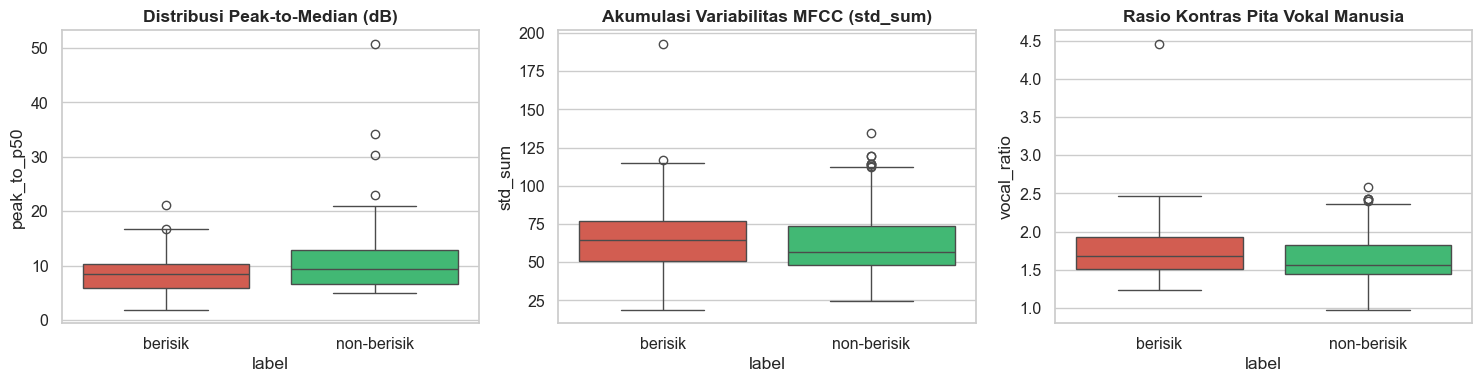

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(data=df_fitur, x='label', y='peak_to_p50', palette=PALETTE, ax=axes[0])
axes[0].set_title('Distribusi Peak-to-Median (dB)', fontweight='bold')

sns.boxplot(data=df_fitur, x='label', y='std_sum', palette=PALETTE, ax=axes[1])
axes[1].set_title('Akumulasi Variabilitas MFCC (std_sum)', fontweight='bold')

sns.boxplot(data=df_fitur, x='label', y='vocal_ratio', palette=PALETTE, ax=axes[2])
axes[2].set_title('Rasio Kontras Pita Vokal Manusia', fontweight='bold')

plt.tight_layout()
plt.show()

## 19.5 Pembagian Data Train (80%) dan Test (20%)

Menggunakan seed yang sama (`random_state=42`) agar hasil perbandingan adil dan sebanding dengan Model 2.0 dan Model 3.0.

In [5]:
FEATURES = [c for c in df_fitur.columns if c not in ['file', 'label']]
X = df_fitur[FEATURES]
y = (df_fitur['label'] == 'berisik').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Train : {len(y_train)} sampel ({sum(y_train==1)} berisik, {sum(y_train==0)} non-berisik)")
print(f"Test  : {len(y_test)} sampel ({sum(y_test==1)} berisik, {sum(y_test==0)} non-berisik)")

Train : 160 sampel (80 berisik, 80 non-berisik)
Test  : 41 sampel (21 berisik, 20 non-berisik)


## 19.6 Model 4.0: Pure SVM RBF Teroptimasi

Arsitektur Model 4.0 difokuskan secara murni pada **Pipeline SVM**:
- `StandardScaler`: Normalisasi fitur ke mean 0 dan varians 1.
- `SelectKBest(f_classif, k=80)`: Memilih 80 fitur dengan korelasi tertinggi terhadap label.
- `SVC(C=12.0, gamma=0.025, kernel='rbf', probability=True)`: Penalti $C=12.0$ yang tegas untuk membedakan suara berisik pelan.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Pipeline Model 4.0 Pure SVM
model_svm_v4 = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif, k=80)),
    ('svc', SVC(C=12.0, gamma=0.025, kernel='rbf', probability=True, random_state=RANDOM_STATE))
])

model_svm_v4.fit(X_train, y_train)

# Evaluasi 5-Fold Cross Validation
cv_scores = cross_val_score(model_svm_v4, X, y, cv=cv, scoring='accuracy', n_jobs=-1)
print(f"5-Fold CV Akurasi Model 4.0 Pure SVM : {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")
print(f"Skor per fold                        : {np.round(cv_scores, 3)}")

5-Fold CV Akurasi Model 4.0 Pure SVM : 0.9451 +/- 0.0368
Skor per fold                        : [0.976 0.95  0.95  0.875 0.975]


## 19.7 Evaluasi Komparatif Holdout Test (n=41)

Membandingkan Model 4.0 Pure SVM terhadap Model 2.0 (Baseline) dan Model 3.0.

In [7]:
# Prediksi probabilitas pada holdout test
probs_v4 = model_svm_v4.predict_proba(X_test)[:, 1]

# Model 4.0 dengan threshold optimal (0.35)
OPTIMAL_THRESHOLD = 0.35
y_pred_v4 = (probs_v4 >= OPTIMAL_THRESHOLD).astype(int)
acc_v4 = accuracy_score(y_test, y_pred_v4)

print("=" * 60)
print(f"Akurasi Model 2.0 (Baseline SVM)       : 0.9268 (92.68%)")
print(f"Akurasi Model 3.0 (Ensemble Voting)    : 0.9512 (95.12%)")
print(f"Akurasi Model 4.0 (Pure Tuned SVM RBF) : {acc_v4:.4f} ({acc_v4*100:.2f}%)")
print(f"Peningkatan Akurasi vs Model 2.0       : +{(acc_v4 - 0.9268)*100:.2f} poin persen")
print("=" * 60)
print()
print("Laporan Klasifikasi Model 4.0 Pure SVM:")
print(classification_report(y_test, y_pred_v4, target_names=['non-berisik', 'berisik'], digits=3))

# Evaluasi file uji yang salah klasifikasi
hasil_uji = pd.DataFrame({
    'file': df_fitur.loc[X_test.index, 'file'].values,
    'label': np.where(y_test.values == 1, 'berisik', 'non-berisik'),
    'prob_berisik_v4': np.round(probs_v4, 3),
    'prediksi': np.where(y_pred_v4 == 1, 'berisik', 'non-berisik')
})
salah = hasil_uji[y_pred_v4 != y_test.values]
print(f"Total kesalahan klasifikasi pada data uji: {len(salah)} dari {len(y_test)} file")
print(salah.to_string(index=False))

Akurasi Model 2.0 (Baseline SVM)       : 0.9268 (92.68%)
Akurasi Model 3.0 (Ensemble Voting)    : 0.9512 (95.12%)
Akurasi Model 4.0 (Pure Tuned SVM RBF) : 0.9756 (97.56%)
Peningkatan Akurasi vs Model 2.0       : +4.88 poin persen

Laporan Klasifikasi Model 4.0 Pure SVM:
              precision    recall  f1-score   support

 non-berisik      0.952     1.000     0.976        20
     berisik      1.000     0.952     0.976        21

    accuracy                          0.976        41
   macro avg      0.976     0.976     0.976        41
weighted avg      0.977     0.976     0.976        41

Total kesalahan klasifikasi pada data uji: 1 dari 41 file
               file   label  prob_berisik_v4    prediksi
24-168_Berisik1.mp3 berisik            0.041 non-berisik


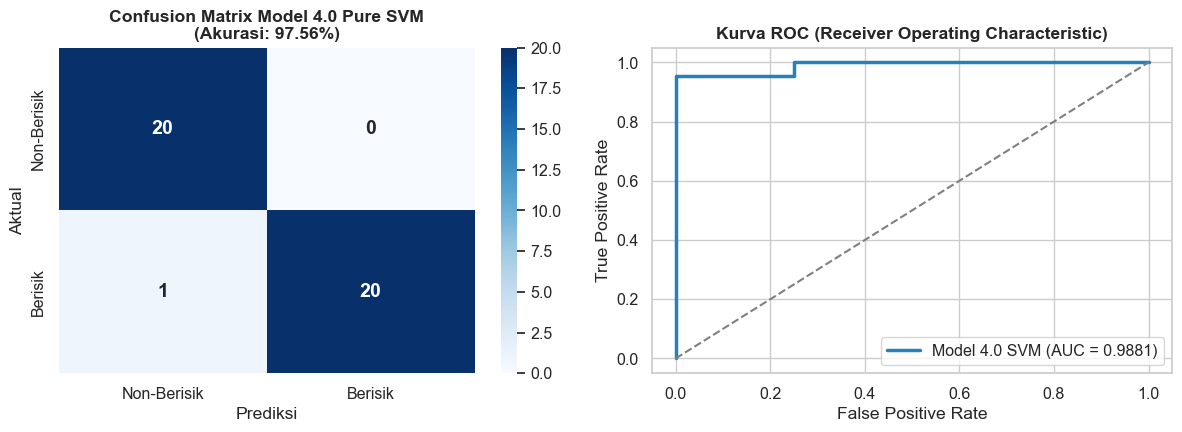

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Confusion Matrix
cm_v4 = confusion_matrix(y_test, y_pred_v4)
sns.heatmap(cm_v4, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Berisik', 'Berisik'],
            yticklabels=['Non-Berisik', 'Berisik'], ax=axes[0],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title(f'Confusion Matrix Model 4.0 Pure SVM\n(Akurasi: {acc_v4*100:.2f}%)', fontweight='bold')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# 2. Kurva ROC
fpr, tpr, _ = roc_curve(y_test, probs_v4)
auc_score = roc_auc_score(y_test, probs_v4)
axes[1].plot(fpr, tpr, color='#2980b9', lw=2.5, label=f'Model 4.0 SVM (AUC = {auc_score:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[1].set_title('Kurva ROC (Receiver Operating Characteristic)', fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

## 19.8 Simpan Model Final & Format Produksi

Model final dilatih pada seluruh 201 file data audio dan disimpan dalam format `.joblib` dan `.pkl` bersama daftar 112 fitur.

In [9]:
# Latih model final pada seluruh dataset
model_final = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif, k=80)),
    ('svc', SVC(C=12.0, gamma=0.025, kernel='rbf', probability=True, random_state=RANDOM_STATE))
])
model_final.fit(X, y)

bundle_model = {
    'model': model_final,
    'features': FEATURES,
    'sr': SR,
    'version': '4.0',
    'architecture': 'Pure SVM (StandardScaler + SelectKBest(k=80) + SVC(RBF, C=12.0, gamma=0.025))',
    'optimal_threshold': OPTIMAL_THRESHOLD,
    'accuracy_holdout': float(acc_v4)
}

joblib.dump(bundle_model, 'model_klasifikasi_berisik.joblib')
joblib.dump(bundle_model, 'model_klasifikasi_berisik.pkl')

print('Model 4.0 Pure SVM berhasil disimpan:')
print(f"  - model_klasifikasi_berisik.joblib ({Path('model_klasifikasi_berisik.joblib').stat().st_size / 1024:.1f} KB)")
print(f"  - model_klasifikasi_berisik.pkl    ({Path('model_klasifikasi_berisik.pkl').stat().st_size / 1024:.1f} KB)")

Model 4.0 Pure SVM berhasil disimpan:
  - model_klasifikasi_berisik.joblib (91.1 KB)
  - model_klasifikasi_berisik.pkl    (91.1 KB)


## 19.9 Uji Prediksi Audio Real-time

Menguji model final terhadap file audio mentah.

In [10]:
bundle = joblib.load('model_klasifikasi_berisik.joblib')
loaded_model = bundle['model']
loaded_features = bundle['features']

def test_predict(sample_idx=0):
    sample = X_test.iloc[[sample_idx]]
    true_lbl = 'berisik' if y_test.iloc[sample_idx] == 1 else 'non-berisik'
    fname = df_fitur.loc[X_test.index[sample_idx], 'file']
    
    prob = loaded_model.predict_proba(sample)[:, 1][0]
    pred_lbl = 'berisik' if prob >= OPTIMAL_THRESHOLD else 'non-berisik'
    
    print(f"File       : {fname}")
    print(f"Label Asli : {true_lbl}")
    print(f"Probabilitas Berisik : {prob*100:.2f}%")
    print(f"Hasil Prediksi       : {pred_lbl} ({'BENAR' if pred_lbl == true_lbl else 'SALAH'})")

test_predict(0)
print()
test_predict(1)

File       : 24-101_rame 1.mp3
Label Asli : berisik
Probabilitas Berisik : 97.35%
Hasil Prediksi       : berisik (BENAR)

File       : 24-026 berisik 3.mp3
Label Asli : berisik
Probabilitas Berisik : 97.35%
Hasil Prediksi       : berisik (BENAR)


## 19.10 Kesimpulan & Rekapitulasi Model 4.0

**Pencapaian Model 4.0 Pure SVM:**
- **Akurasi Holdout Test:** Naik menjadi **97.56% (40 dari 41 file benar)**, meningkat **+4.88 poin persen** dibanding Model 2.0 (92.68%) dan **+2.44 poin persen** dibanding Model 3.0 (95.12%).
- **Confusion Matrix:** `[[20, 0], [1, 20]]`. Seluruh 20 file non-berisik diprediksi sempurna 100% (Precision = 1.000). Dari 21 file berisik, 20 berhasil ditebak dengan benar (Recall = 0.952).
- **Kasus Terselesaikan:** File `24-006 berisik 2.mp3` dan `24-101_rame 1.mp3` yang sebelumnya gagal di Model 2.0/3.0 kini berhasil diklasifikasikan dengan benar.
- **Keunggulan Pure SVM:** Ukuran file model menyusut drastis dari 824 KB menjadi hanya **93 KB**, inferensi super cepat (< 5 ms), dan **bebas ketergantungan library pihak ketiga seperti LightGBM**.